# Heart Disease Prediction Analysis
This notebook analyzes the heart.csv dataset to predict heart disease.

## Part (a): Data Loading and Cleaning

In [1]:
# Load dataset
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
df = pd.read_csv('heart.csv')
# Rename columns to descriptive names
df = df.rename(columns={'age':'Age','sex':'Sex','cp':'ChestPainType','trestbps':'RestingBP','chol':'Cholesterol','thalach':'MaxHR','exang':'ExerciseAngina','target':'HeartDisease'})
print(df.head(10))
print('Shape:', df.shape)
print(df.dtypes)

   Age  Sex  ChestPainType  RestingBP  Cholesterol  fbs  restecg  MaxHR  \
0   63    1              3        145          233    1        0    150   
1   37    1              2        130          250    0        1    187   
2   41    0              1        130          204    0        0    172   
3   56    1              1        120          236    0        1    178   
4   57    0              0        120          354    0        1    163   
5   57    1              0        140          192    0        1    148   
6   56    0              1        140          294    0        0    153   
7   44    1              1        120          263    0        1    173   
8   52    1              2        172          199    1        1    162   
9   57    1              2        150          168    0        1    174   

   ExerciseAngina  oldpeak  slope  ca  thal  HeartDisease  
0               0      2.3      0   0     1             1  
1               0      3.5      0   0     2           

In [2]:
# Check missing values
print('Missing values:'); print(df.isnull().sum())
# Handle zero values in Cholesterol and RestingBP as missing -> replace with median
for col in ['Cholesterol','RestingBP']:
    med = df.loc[df[col]!=0, col].median()
    df[col] = df[col].replace(0, med)
print(df[['Cholesterol','RestingBP']].describe())

Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
fbs               0
restecg           0
MaxHR             0
ExerciseAngina    0
oldpeak           0
slope             0
ca                0
thal              0
HeartDisease      0
dtype: int64
       Cholesterol   RestingBP
count   303.000000  303.000000
mean    246.264026  131.623762
std      51.830751   17.538143
min     126.000000   94.000000
25%     211.000000  120.000000
50%     240.000000  130.000000
75%     274.500000  140.000000
max     564.000000  200.000000


In [3]:
# Class distribution
print(df['HeartDisease'].value_counts())
print('Balanced?' , 'Yes' if df['HeartDisease'].value_counts(normalize=True).min()>0.4 else 'Imbalanced')

HeartDisease
1    165
0    138
Name: count, dtype: int64
Balanced? Yes


## Part (b): EDA

In [4]:
# Summary statistics
print(df.describe())

              Age         Sex  ChestPainType   RestingBP  Cholesterol  \
count  303.000000  303.000000     303.000000  303.000000   303.000000   
mean    54.366337    0.683168       0.966997  131.623762   246.264026   
std      9.082101    0.466011       1.032052   17.538143    51.830751   
min     29.000000    0.000000       0.000000   94.000000   126.000000   
25%     47.500000    0.000000       0.000000  120.000000   211.000000   
50%     55.000000    1.000000       1.000000  130.000000   240.000000   
75%     61.000000    1.000000       2.000000  140.000000   274.500000   
max     77.000000    1.000000       3.000000  200.000000   564.000000   

              fbs     restecg       MaxHR  ExerciseAngina     oldpeak  \
count  303.000000  303.000000  303.000000      303.000000  303.000000   
mean     0.148515    0.528053  149.646865        0.326733    1.039604   
std      0.356198    0.525860   22.905161        0.469794    1.161075   
min      0.000000    0.000000   71.000000        0

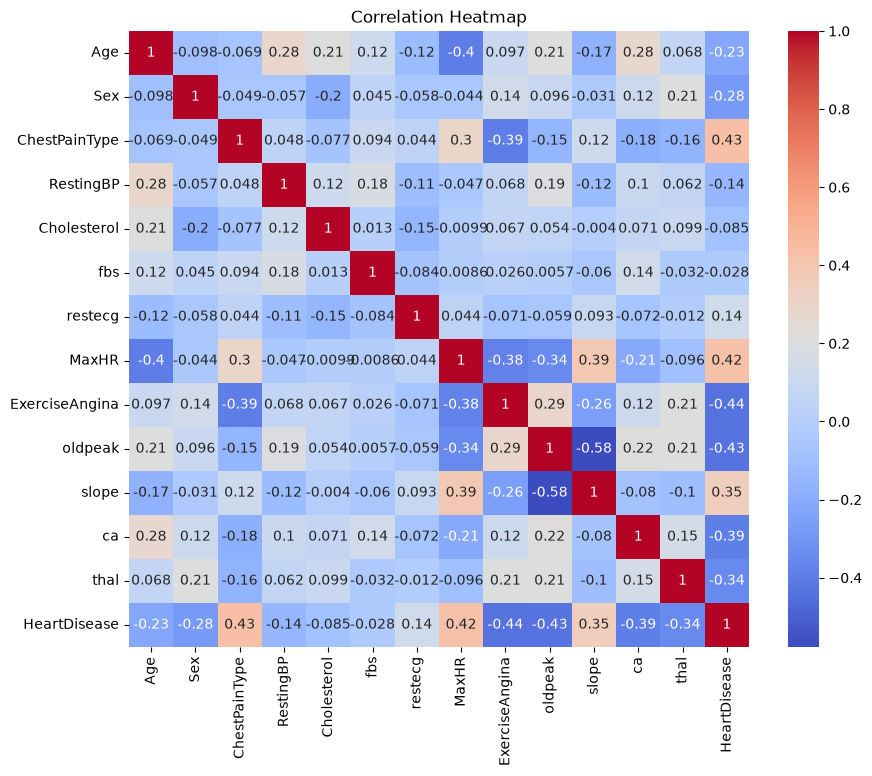

In [5]:
# Correlation heatmap
num = df.select_dtypes(include=np.number)
plt.figure(figsize=(10,8)); sns.heatmap(num.corr(), annot=True, cmap='coolwarm'); plt.title('Correlation Heatmap'); plt.show()

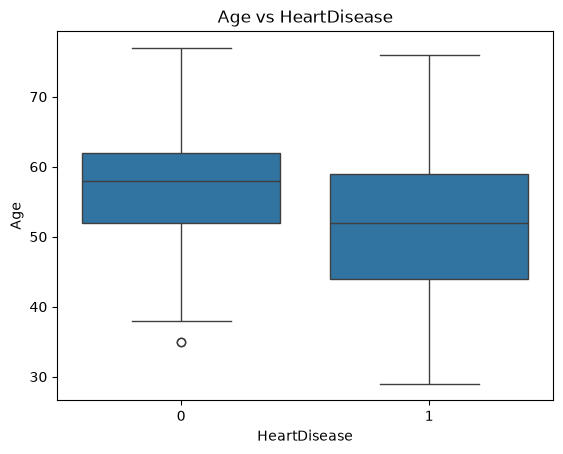

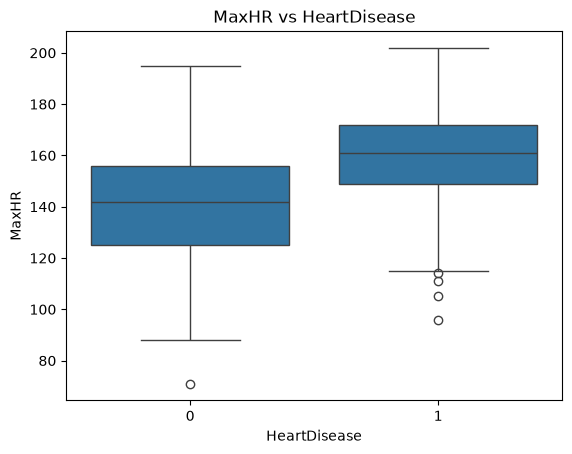

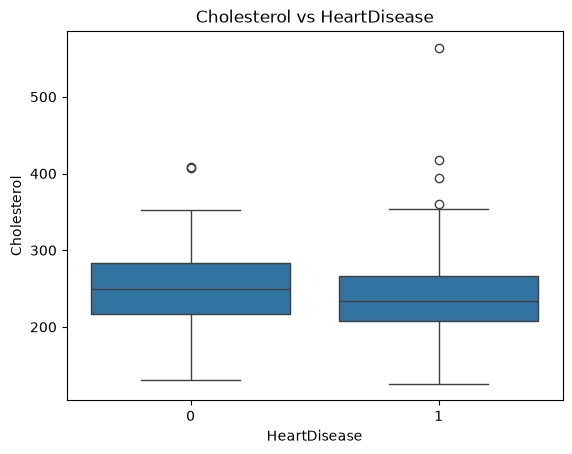

In [6]:
# Relationship of Age, MaxHR, Cholesterol with target
for col in ['Age','MaxHR','Cholesterol']:
    plt.figure(); sns.boxplot(x='HeartDisease', y=col, data=df); plt.title(col+' vs HeartDisease'); plt.show()

In [7]:
# Encode categorical variables
cat_cols = ['ChestPainType','thal','slope','restecg']
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print(df.head())

   Age  Sex  RestingBP  Cholesterol  fbs  MaxHR  ExerciseAngina  oldpeak  ca  \
0   63    1        145          233    1    150               0      2.3   0   
1   37    1        130          250    0    187               0      3.5   0   
2   41    0        130          204    0    172               0      1.4   0   
3   56    1        120          236    0    178               0      0.8   0   
4   57    0        120          354    0    163               1      0.6   0   

   HeartDisease  ChestPainType_1  ChestPainType_2  ChestPainType_3  thal_1  \
0             1            False            False             True    True   
1             1            False             True            False   False   
2             1             True            False            False   False   
3             1             True            False            False   False   
4             1            False            False            False   False   

   thal_2  thal_3  slope_1  slope_2  restecg_1  re

## Part (c): Modeling

In [8]:
# Split data
from sklearn.model_selection import train_test_split
X = df.drop('HeartDisease', axis=1); y = df['HeartDisease']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(242, 19) (61, 19)


In [9]:
# Decision Tree with max_depth 3,5,None
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
for depth in [3,5,None]:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train, y_train)
    acc = accuracy_score(y_test, dt.predict(X_test))
    print('max_depth', depth, 'accuracy', acc)

max_depth 3 accuracy 0.7704918032786885
max_depth 5 accuracy 0.8032786885245902
max_depth None accuracy 0.8032786885245902


In [10]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
print('LR accuracy', accuracy_score(y_test, lr.predict(X_test)))

LR accuracy 0.9016393442622951


C:\Users\opolot\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Part (d): Evaluation

DecisionTree
              precision    recall  f1-score   support

           0       0.70      0.90      0.79        29
           1       0.88      0.66      0.75        32

    accuracy                           0.77        61
   macro avg       0.79      0.78      0.77        61
weighted avg       0.79      0.77      0.77        61



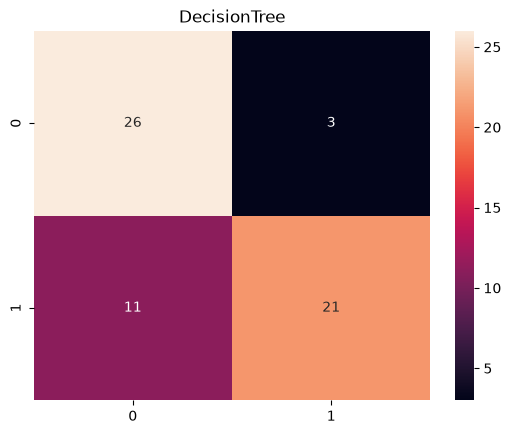

LogisticRegression
              precision    recall  f1-score   support

           0       0.87      0.93      0.90        29
           1       0.93      0.88      0.90        32

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61



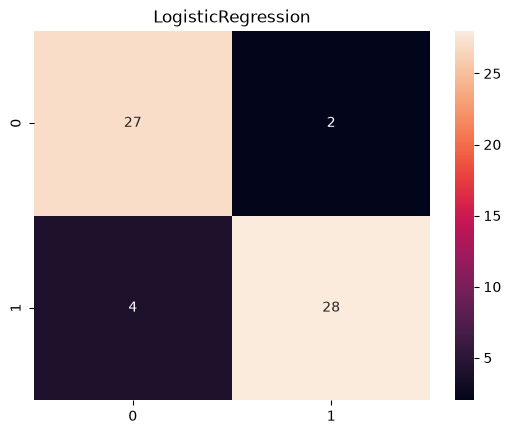

In [11]:
# Confusion matrices and classification reports
from sklearn.metrics import confusion_matrix, classification_report
best_dt = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train,y_train)
for name, model in [('DecisionTree',best_dt),('LogisticRegression',lr)]:
    pred = model.predict(X_test)
    print(name); print(classification_report(y_test,pred))
    cm = confusion_matrix(y_test,pred)
    sns.heatmap(cm, annot=True, fmt='d'); plt.title(name); plt.show()

In [12]:
# Comparison table
from sklearn.metrics import precision_score, recall_score, f1_score
rows=[]
for name,model in [('DT3',DecisionTreeClassifier(max_depth=3,random_state=42).fit(X_train,y_train)),
                   ('DT5',DecisionTreeClassifier(max_depth=5,random_state=42).fit(X_train,y_train)),
                   ('DTNone',DecisionTreeClassifier(max_depth=None,random_state=42).fit(X_train,y_train)),
                   ('LR',lr)]:
    p=model.predict(X_test)
    rows.append({'Model':name,'Accuracy':accuracy_score(y_test,p),'Precision':precision_score(y_test,p),
                 'Recall':recall_score(y_test,p),'F1':f1_score(y_test,p)})
print(pd.DataFrame(rows))

    Model  Accuracy  Precision   Recall        F1
0     DT3  0.770492   0.875000  0.65625  0.750000
1     DT5  0.803279   0.833333  0.78125  0.806452
2  DTNone  0.803279   0.833333  0.78125  0.806452
3      LR  0.901639   0.933333  0.87500  0.903226


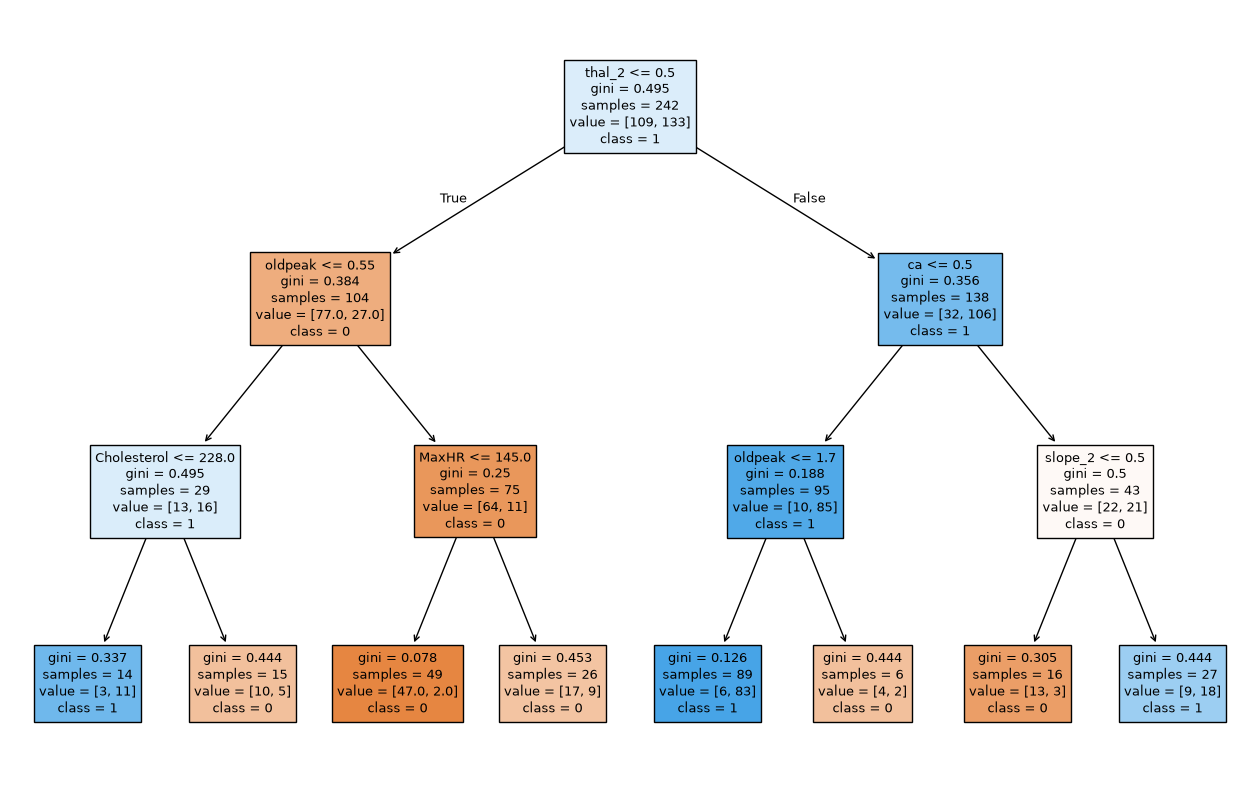

In [13]:
# Visualize best Decision Tree (max_depth=3)
from sklearn.tree import plot_tree
plt.figure(figsize=(16,10)); plot_tree(best_dt, feature_names=X.columns, class_names=['0','1'], filled=True, max_depth=3); plt.show()